In [1]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

def prob_to_angle(prob):
    return 2 * np.arcsin(np.sqrt(prob))

def build_A(prob, n_days):
    angle = prob_to_angle(prob)
    qc = QuantumCircuit(n_days)
    for i in range(n_days):
        qc.ry(angle, i)
    return qc

# print(Statevector.from_instruction(build_A(0.3, 1)).probabilities_dict())
# print(Statevector.from_instruction(build_A(0.2, 3)).probabilities_dict())

def build_A_marked(prob, n_days):
    qc = QuantumCircuit(n_days + 1)
    qc.compose(build_A(prob, n_days), range(n_days), inplace=True)
    days = list(range(n_days))
    qc.x(days)
    qc.mcx(days, n_days)                     # objective=1 only if all days were 0
    qc.x(days)
    qc.x(n_days)                             # flip: objective=1 if any day is 1
    return qc

# A = build_A_marked(0.2, 3)
# print(Statevector.from_instruction(A).probabilities([3]))   # expect [0.512, 0.488]

def build_A_markov():
    p_ns = 0.10                        # P(Stressed | Normal)
    p_ss = 0.80                        # P(Stressed | Stressed)
    a_ns = prob_to_angle(p_ns)
    a_ss = prob_to_angle(p_ss)
    qc = QuantumCircuit(3)
    qc.ry(a_ns, 0)
    for d in range(1, 3):
        qc.x(d - 1)
        qc.cry(a_ns, d - 1, d)
        qc.x(d - 1)
        qc.cry(a_ss, d - 1, d)
    return qc

# print(Statevector(build_A_markov()).probabilities([2])[1])   # expect 0.219

def build_A_markov_marked():
    qc = QuantumCircuit(4)
    qc.compose(build_A_markov(), [0, 1, 2], inplace=True)
    qc.cx(2, 3)
    return qc

# print(Statevector(build_A_markov_marked()).probabilities([3])[1])   # expect 0.219

In [2]:
from itertools import product
from scipy.stats import norm

MU = np.array([0.0005, -0.0020])     # mean daily log return: Normal, Stressed
SIGMA = np.array([0.010, 0.030])     # daily std dev: Normal, Stressed
LOSS_THRESHOLD = -0.05

def loss_probs():
    q = {}
    for path in product(range(2), repeat=3):    # (day1, day2, day3), 0=Normal, 1=Stressed
        total_mean = sum(MU[i] for i in path)
        total_std = np.sqrt(sum(SIGMA[i] ** 2 for i in path))
        q[path] = norm.cdf(LOSS_THRESHOLD, loc=total_mean, scale=total_std)
    return q

# q = loss_probs()
# print(q[(0, 0, 0)], q[(1, 1, 1)])     # expect about 0.00147 and 0.19856

from qiskit.circuit.library import RYGate

def build_A_markov_loss():
    q = loss_probs()
    qc = QuantumCircuit(4)
    qc.compose(build_A_markov(), [0, 1, 2], inplace=True)
    for path, q_path in q.items():
        zeros = [i for i, s in enumerate(path) if s == 0]
        if zeros:
            qc.x(zeros)
        qc.append(RYGate(prob_to_angle(q_path)).control(3), [0, 1, 2, 3])
        if zeros:
            qc.x(zeros)
    return qc

# print(Statevector(build_A_markov_loss()).probabilities([3])[1])   # expect ≈ 0.03482

In [3]:
from qiskit.circuit.library import ZGate

def reflect_zero(n):
    qc = QuantumCircuit(n)
    qc.x(range(n))
    mcz = ZGate().control(n - 1)
    qc.append(mcz, list(range(n)))
    qc.x(range(n))
    return qc

# from qiskit.quantum_info import Operator

# print(np.round(Operator(reflect_zero(2)).data.real, 3))

# qc = QuantumCircuit(2)
# qc.h([0, 1])
# qc.compose(reflect_zero(2), inplace=True)
# print(np.round(Statevector(qc).data.real, 3))

def grover_op(A_marked, flag_qubit):
    n = A_marked.num_qubits
    qc = QuantumCircuit(n)
    qc.z(flag_qubit)
    a_cross = A_marked.inverse()
    qc.compose(a_cross, inplace=True)
    s0 = reflect_zero(n)
    qc.compose(s0, inplace=True)
    a_prime = A_marked
    qc.compose(a_prime, inplace=True)
    return qc

# p = 1 - (1 - 0.2) ** 3
# theta = np.arcsin(np.sqrt(p))
# A = build_A_marked(0.2, 3)
# Q = grover_op(A, 3)

# for m in range(5):
#     qc = QuantumCircuit(A.num_qubits)
#     qc.compose(A, inplace=True)
#     for _ in range(m):
#         qc.compose(Q, inplace=True)
#     measured = Statevector(qc).probabilities([3])[1]
#     expected = np.sin((2*m + 1) * theta) ** 2
#     # print(m, round(measured, 4), round(expected, 4))

# p = p_true = 0.219
p = p_true = 0.034819255
theta = np.arcsin(np.sqrt(p))
# A = build_A_markov_marked()            # the Markov model
A = build_A_markov_loss()              # the Markov model with loss probabilities
Q = grover_op(A, 3)

for m in range(5):
    qc = QuantumCircuit(A.num_qubits)
    qc.compose(A, inplace=True)
    for _ in range(m):
        qc.compose(Q, inplace=True)
    measured = Statevector(qc).probabilities([3])[1]
    expected = np.sin((2*m + 1) * theta) ** 2
    # print(m, round(measured, 4), round(expected, 4))

from qiskit import transpile

def resources(qc):
    t = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    return t.num_qubits, t.count_ops().get("cx", 0), t.depth()

print("A':", resources(A))
print("Q :", resources(Q))

for m in [0, 1, 2, 4, 8, 16]:
    qc = QuantumCircuit(A.num_qubits)
    qc.compose(A, inplace=True)
    for _ in range(m):
        qc.compose(Q, inplace=True)
    # print(m, resources(qc))

A': (4, 168, 598)
Q : (4, 350, 1213)


In [4]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()

def count_hits(A, Q, m, shots, flag_qubit):
    n = A.num_qubits
    qc = QuantumCircuit(n, 1)
    qc.compose(A, inplace=True)
    for _ in range(m):
        qc.compose(Q, inplace=True)
    qc.measure(flag_qubit, 0)
    result = sampler.run([qc], shots=shots).result()
    counts = result[0].data.c.get_counts()
    return counts.get('1', 0)

_prob_cache = {}

def count_hits_fast(A, Q, m, shots, flag_qubit):
    if m not in _prob_cache:
        qc = QuantumCircuit(A.num_qubits)
        qc.compose(A, inplace=True)
        for _ in range(m):
            qc.compose(Q, inplace=True)
        _prob_cache[m] = Statevector(qc).probabilities([flag_qubit])[1]
    return np.random.binomial(shots, _prob_cache[m])

def log_likelihood(theta, ms, hs, NS):
    total = 0
    for k in range(len(ms)):
        m = ms[k]
        h = hs[k]
        N = NS[k]
        p = np.sin((2*m + 1) * theta) ** 2
        p = np.clip(p, 1e-12, 1 - 1e-12)
        total += h * np.log(p) + (N - h) * np.log(1 - p)
    return total

# true_theta = np.arcsin(np.sqrt(0.488))
# ms = [0, 1, 2, 4]
# NS = [100] * 4
# hs = [np.random.binomial(N, np.sin((2*m + 1) * true_theta) ** 2) for m, N in zip(ms, NS)]

# thetas = np.linspace(0, np.pi / 2, 1000)
# lls = [log_likelihood(t, ms, hs, NS) for t in thetas]
# print(thetas[np.argmax(lls)], true_theta)   # should be close, ~0.77

In [5]:
def mlae(A, Q, ms, shots, flag_qubit):
    hs = []
    for m in ms:
        # h = count_hits(A, Q, m, shots, flag_qubit)
        h = count_hits_fast(A, Q, m, shots, flag_qubit)
        hs.append(h)
    NS = [shots] * len(ms)
    thetas = np.linspace(0, np.pi / 2, 10_000)
    lls = log_likelihood(thetas, ms, hs, NS)
    theta_hat = thetas[np.argmax(lls)]
    p_hat = np.sin(theta_hat) ** 2
    N_queries = sum(shots * (2*m + 1) for m in ms)
    return p_hat, N_queries


p_hat, N = mlae(A, Q, [0, 1, 2, 4], 100, 3)
# print(p_hat, N)   

In [6]:
def lis(k):
    result = []
    for i in range(k + 1):
        result.append(i)
    return result

def eis(k):
    result = [0]
    for i in range(k):
        result.append(2 ** i)
    return result

# print(lis(4))   # [0, 1, 2, 3, 4]
# print(eis(4))   # [0, 1, 2, 4, 8]

In [7]:
def rmse_mlae(A, Q, ms, shots, flag_qubit, p_true, trials):
    p_hats = []
    for _ in range(trials):
        p_hat, N = mlae(A, Q, ms, shots, flag_qubit)
        p_hats.append(p_hat)
    rmse = np.sqrt(np.mean((np.array(p_hats) - p_true) ** 2))
    return rmse, N

# p_true = 1 - 0.8 ** 3
# print(rmse_mlae(A, Q, eis(2), 100, 3, p_true, 20))
# print(rmse_mlae(A, Q, eis(4), 100, 3, p_true, 20))

def rmse_classical(N, p_true, trials):
    p_hats = []
    for _ in range(trials):
        p_hat = np.random.binomial(N, p_true) / N
        p_hats.append(p_hat)
    rmse = np.sqrt(np.mean((np.array(p_hats) - p_true) ** 2))
    return rmse

_prob_cache.clear()
results = {"LIS": [], "EIS": [], "Classical": []}
for K in range(1, 6):
    rmse, N = rmse_mlae(A, Q, lis(K), 100, 3, p_true, 50)
    results["LIS"].append((N, rmse))
    rmse, N = rmse_mlae(A, Q, eis(K), 100, 3, p_true, 50)
    results["EIS"].append((N, rmse))
    rmse = rmse_classical(N, p_true, 50)
    results["Classical"].append((N, rmse))

# print(len(results["LIS"]), results["LIS"])
# print(len(results["EIS"]), results["EIS"])
# print(len(results["Classical"]), results["Classical"])

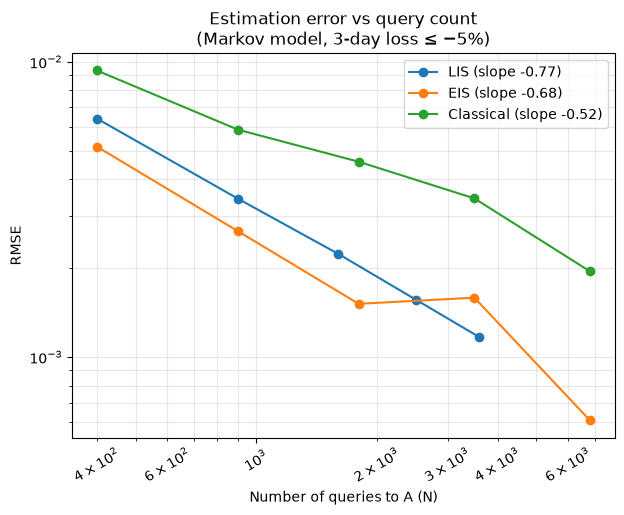

In [8]:
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.figure(figsize=(7, 5))

for name, points in results.items():
    Ns = [n for n, r in points]        # x values: number of queries
    rmses = [r for n, r in points]     # y values: error
    slope = np.polyfit(np.log(Ns), np.log(rmses), 1)[0]
    plt.loglog(Ns, rmses, "o-", label=f"{name} (slope {slope:.2f})")

plt.xlabel("Number of queries to A (N)")
plt.ylabel("RMSE")
plt.title("Estimation error vs query count\n(Markov model, 3-day loss ≤ −5%)")
# plt.title("Estimation error vs query count (Markov model)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.gca().tick_params(axis="x", which="both", rotation=30)
# plt.savefig(OUTPUT_DIR / "rmse_vs_N_markov.png", dpi=200, bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "rmse_vs_N_loss.png", dpi=200, bbox_inches="tight")
plt.show()